Construir un script que reciba un texto y lo convierta en un vector a traves de algun embedding. Mostrar espacio, graficar vectores embedidos

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2478.71it/s]


Palabras: 6
Dimensiones de cada embedding: 384

El:
[ 6.90493360e-02  8.91283154e-02 -7.39747956e-02  6.44040927e-02
 -1.16400467e-02 -2.00163960e-01  4.80655104e-01  1.45750985e-01
  1.40414014e-01  2.67589334e-02  1.76981404e-01 -1.82130620e-01
  8.74916911e-02 -1.37975544e-01 -1.09124899e-01 -3.42987627e-02
 -1.61455218e-02  9.96818542e-02  1.79526710e-03 -1.15328096e-01
  4.08774614e-01 -6.30039945e-02 -1.88324954e-02 -2.52889171e-02
 -1.16789795e-01 -7.48882815e-02 -4.82986383e-02  5.15206642e-02
 -1.71273828e-01 -4.43476111e-01  1.14854842e-01 -1.54734597e-01
  3.55675697e-01  2.62098283e-01 -9.57200900e-02  9.18077230e-02
  3.57482992e-02 -8.08320865e-02 -5.13687916e-02 -1.21884190e-01
  5.71461134e-02 -3.59005332e-02  2.22339537e-02  2.19450250e-01
  1.95404693e-01  7.39561841e-02  2.34403312e-02  8.14478472e-03
 -3.58748175e-02  1.46152988e-01  1.88231468e-01 -5.90633266e-02
 -1.53623462e-01 -1.32974774e-01  6.38063252e-02  2.15157673e-01
  1.36919498e-01  1.90261126e-01 -6.02

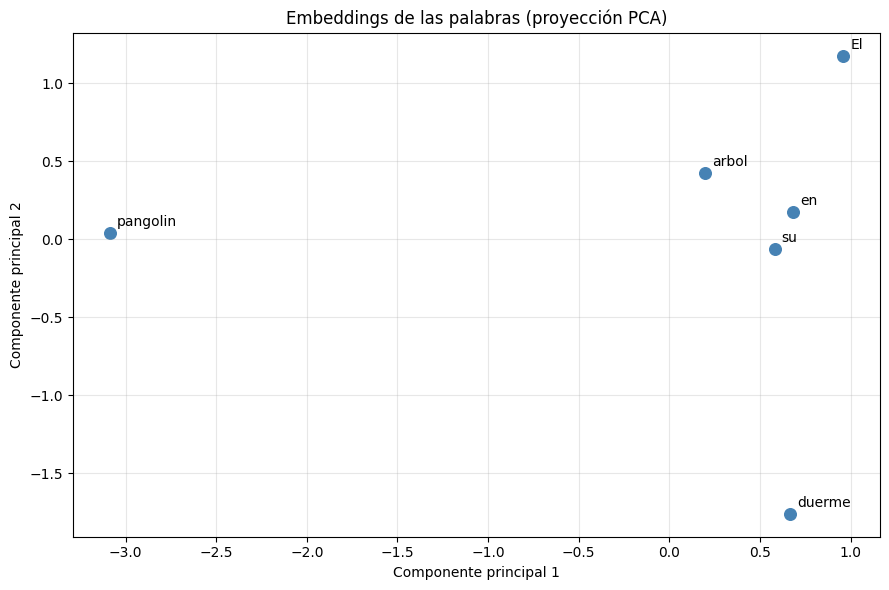

In [3]:
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA

# Si hace falta instalar las dependencias, ejecuta en otra celda:
# %pip install sentence-transformers scikit-learn matplotlib

import matplotlib.pyplot as plt

import re

# Modelo compatible con español
modelo = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")

texto_entrada = texto = "El pangolin duerme en su arbol"
palabras = re.findall(r"\w+", texto_entrada, flags=re.UNICODE)

if not palabras:
    raise ValueError("Escribe una frase que contenga al menos una palabra.")

# Un vector embedding por palabra
embeddings_palabras = modelo.encode(palabras, convert_to_numpy=True)

print(f"Palabras: {len(palabras)}")
print(f"Dimensiones de cada embedding: {embeddings_palabras.shape[1]}")

for palabra, embedding in zip(palabras, embeddings_palabras):
    print(f"\n{palabra}:")
    print(embedding)

if len(palabras) >= 2:
    # Proyectar los embeddings al plano para visualizarlos
    puntos = PCA(n_components=2).fit_transform(embeddings_palabras)

    plt.figure(figsize=(9, 6))
    plt.scatter(puntos[:, 0], puntos[:, 1], color="steelblue", s=70)

    for palabra, (x, y) in zip(palabras, puntos):
        plt.annotate(palabra, (x, y), xytext=(5, 5), textcoords="offset points")

    plt.title("Embeddings de las palabras (proyección PCA)")
    plt.xlabel("Componente principal 1")
    plt.ylabel("Componente principal 2")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("\nSe necesita más de una palabra para graficar la proyección PCA.")